# Grounding an LLM in UniProt: a minimal retrieval-augmented generation (RAG) system, measured

**Module 04.3 · my implementation**, Seid Adem

> **Why this matters, in plain language.** An LLM answering from memory ("closed-book") produces fluent text whether
> or not it knows the answer, as [notebook 01](01_tokens_genes_dna_proteins.ipynb) showed. **Retrieval-augmented
> generation (RAG)** changes the job: first *search* a trusted source for relevant passages, then ask the model to
> answer **only from those passages** and to **cite** them. The model becomes a reader, not an oracle.
> ([Lesson 5](../LESSONS.md))

The trusted source here is **UniProt**, EMBL-EBI's curated protein database: 17,000+ reviewed human entries. The
generator is the same small open model as before (Qwen2.5-0.5B-Instruct, runs on a laptop). Rather than show a few
nice examples, I **grade** the system on questions with known answers:

| Test | Questions | Correct answer |
|---|---|---|
| A · identifier lookup | "What is the UniProt accession of the protein encoded by *GENE*?" | the accession |
| B · reverse lookup | "Which human gene encodes the protein *NAME*?" | the gene symbol |
| C · unanswerable | questions about **made-up genes** | "Not found in UniProt." |

The search, prompt and grading helpers are in [`src/dsls/rag.py`](../../../src/dsls/rag.py) (unit-tested).

In [1]:
import io
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import transformers
from IPython.display import display
from transformers import AutoModel, AutoModelForCausalLM, AutoTokenizer

from dsls.ebi_api import uniprot
from dsls.rag import (
    SYSTEM_PROMPT,
    HybridIndex,
    cited_accessions,
    evidence_overlap,
    is_abstention,
    rag_messages,
    uniprot_documents,
)
from dsls.textclf import pick_device

warnings.filterwarnings("ignore", category=FutureWarning)
transformers.logging.set_verbosity_error()
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 160)
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
SEED = 0
DEVICE = pick_device()

## 1 · The knowledge base: one citable passage per UniProt entry

In [2]:
response = uniprot().get("uniprotkb/stream", params={
    "query": "organism_id:9606 AND reviewed:true", "format": "tsv",
    "fields": "accession,gene_primary,protein_name,length,cc_function,cc_subcellular_location,sequence"})  # fmt: skip
human = pd.read_csv(io.StringIO(response.text), sep="\t")
human.columns = ["accession", "gene", "protein", "length", "function", "location", "sequence"]
docs = uniprot_documents(human)
print(f"{len(human):,} reviewed human entries (fetched {response.fetched_at[:10]}) → {len(docs):,} passages "
      f"(entries with a gene symbol and a function description)")  # fmt: skip
print("\nexample passage:\n", docs.loc[docs["gene"] == "TP53", "text"].item())

20,429 reviewed human entries (fetched 2026-11-08) → 17,346 passages (entries with a gene symbol and a function description)

example passage:
 UniProt P04637 | Gene: TP53 | Protein: Cellular tumor antigen p53 | Function: Multifunctional transcription factor that induces cell cycle arrest, DNA repair or apoptosis upon binding to its target DNA sequence. Acts as a tumor suppressor in many tumor types; induces growth arrest or apoptosis depending on the physiological circumstances and cell type. Negatively regulates cell division by controlling expression of a set of genes required for this process. One of the activated genes is an inhibitor of cyclin-dependent kinases. Apoptosis induction seems to be mediated eith


## 2 · Retrieval: finding the right passage

> **In plain language.** Three ways to search 17,000 passages:
> * **keywords (TF-IDF):** passages sharing the question's rarer words score highest;
> * **neural sentence embeddings (MiniLM):** a small transformer turns each text into a vector that captures meaning,
>   so "heart attack" can match "myocardial infarction". This is what most RAG tutorials use;
> * **hybrid:** if the question contains a known identifier (a gene symbol), take that entry first, then keywords.
>
> **Recall@k** = how often the correct passage is among the top *k* results. If retrieval misses, the generator never
> sees the answer.

200 random entries, two question styles:

embedded 17,346 passages with MiniLM in 74 s


,questions,search,recall@1,recall@3
0,A · gene symbol in question,keywords (TF-IDF),0.510,0.690
1,A · gene symbol in question,neural embeddings (MiniLM),0.125,0.180
2,A · gene symbol in question,"hybrid: exact gene symbol, then keywords",1.000,1.000
3,B · protein name in question,keywords (TF-IDF),0.680,0.860
4,B · protein name in question,neural embeddings (MiniLM),0.370,0.515
5,B · protein name in question,"hybrid: exact gene symbol, then keywords",0.660,0.860


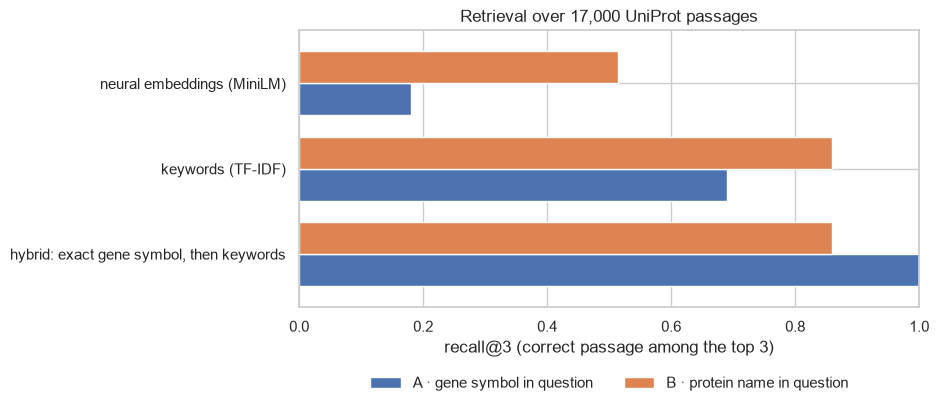

How MiniLM's tokeniser sees CDKN2A: ['cd', '##k', '##n', '##2', '##a']


In [3]:
rng = np.random.default_rng(SEED)
qi = rng.choice(len(docs), 200, replace=False)
questions = {
    "A · gene symbol in question": [f"What is the UniProt accession of the human protein encoded by the gene {g}?" for g in docs["gene"].values[qi]],
    "B · protein name in question": [f"Which human gene encodes the protein '{p}'?" for p in docs["protein"].values[qi]],
}  # fmt: skip

index = HybridIndex(docs["text"], docs["gene"])

emb_tok = AutoTokenizer.from_pretrained("sentence-transformers/all-MiniLM-L6-v2")
emb_model = AutoModel.from_pretrained("sentence-transformers/all-MiniLM-L6-v2").to(DEVICE).eval()


@torch.no_grad()
def embed(texts, batch_size=256):
    out = []
    for i in range(0, len(texts), batch_size):
        enc = emb_tok(
            texts[i : i + batch_size], padding=True, truncation=True, max_length=256, return_tensors="pt"
        ).to(DEVICE)
        hidden, mask = emb_model(**enc).last_hidden_state, enc["attention_mask"].unsqueeze(-1)
        out.append(torch.nn.functional.normalize((hidden * mask).sum(1) / mask.sum(1), dim=1).cpu())
    return torch.cat(out).numpy()


start = time.perf_counter()
doc_vectors = embed(docs["text"].tolist())
print(f"embedded {len(docs):,} passages with MiniLM in {time.perf_counter() - start:.0f} s")

searchers = {
    "keywords (TF-IDF)": lambda q, k: [index.search(x, k, use_identifiers=False) for x in q],
    "neural embeddings (MiniLM)": lambda q, k: list(np.argsort(-(embed(q) @ doc_vectors.T), axis=1)[:, :k]),
    "hybrid: exact gene symbol, then keywords": lambda q, k: [index.search(x, k) for x in q],
}
rows = []
for qname, qs in questions.items():
    for sname, search in searchers.items():
        top = np.array(search(qs, 3))
        rows.append({"questions": qname, "search": sname, "recall@1": np.mean(top[:, 0] == qi),
                     "recall@3": np.mean((top == qi[:, None]).any(1))})  # fmt: skip
recall = pd.DataFrame(rows)
display(recall.round(3))

ax = recall.pivot(index="search", columns="questions", values="recall@3").plot.barh(
    figsize=(8, 3.6), width=0.75
)
ax.set(
    xlabel="recall@3 (correct passage among the top 3)",
    ylabel="",
    xlim=(0, 1),
    title="Retrieval over 17,000 UniProt passages",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
plt.savefig(FIGURES / "02_retrieval_recall.png", dpi=150, bbox_inches="tight")
plt.show()

g = "CDKN2A"
print(f"How MiniLM's tokeniser sees {g}:", emb_tok.tokenize(g))

**The popular choice was the worst choice here.** Neural sentence embeddings (MiniLM) found the right passage in the
top 3 for only **18 %** of gene-symbol questions, against 69 % for plain keyword search. The last line shows why:
MiniLM's tokeniser turns `CDKN2A` into `cd · ##k · ##n · ##2 · ##a`, five fragments with no meaning
([notebook 01](01_tokens_genes_dna_proteins.ipynb) measured the same problem across 20,000 symbols). Embeddings are
built to match *meaning*, and an identifier has none: it must match *exactly*.

**The hybrid search fixes this with one rule.** If a word in the question is a known gene symbol, rank that entry
first: recall rises to **100 %**. For protein-name questions, which have no symbol to match, the hybrid is keyword
search (top-3 recall 0.86) and MiniLM is again behind (0.52). Keyword misses come from generic words: "protein" and
"growth factor" pull in short, unrelated passages.

> **In plain language.** For databases full of identifiers (genes, accessions, compounds), start with exact lookup
> and keywords; add neural search for questions phrased in free text. Test retrieval *on its own* before blaming
> or praising the LLM.

## 3 · Generation: closed-book vs RAG

The same model answers each question twice, greedily (no randomness):
* **closed-book:** just the question;
* **RAG:** the top 3 passages from the hybrid search, numbered, with instructions to use only them, cite accessions
  and say "Not found in UniProt." otherwise.

Grading is automatic: test A is correct if the right accession appears in the answer; test B if the right gene
symbol appears as a whole word.

In [4]:
LLM = "Qwen/Qwen2.5-0.5B-Instruct"
tok = AutoTokenizer.from_pretrained(LLM)
llm = AutoModelForCausalLM.from_pretrained(LLM, torch_dtype=torch.float32).to(DEVICE).eval()


@torch.no_grad()
def generate(messages, max_new_tokens=48):
    ids = tok.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt").to(DEVICE)
    out = llm.generate(
        ids, max_new_tokens=max_new_tokens, do_sample=False, top_p=None, top_k=None, temperature=None
    )
    return tok.decode(out[0, ids.shape[1] :], skip_special_tokens=True).strip()


def closed_book(question):
    return generate([{"role": "user", "content": question}])


def with_rag(question, k=3, system=SYSTEM_PROMPT):
    hits = index.search(question, k)
    return generate(rag_messages(question, docs["text"].values[hits].tolist(), system)), hits


tests = {
    "A · accession of gene": (lambda i: f"What is the UniProt accession of the human protein encoded by the gene {docs['gene'][i]}? "
                              "Answer with the accession only.", lambda i, a: docs["accession"][i] in a),
    "B · gene encoding protein": (lambda i: f"Which human gene encodes the protein '{docs['protein'][i]}'? Answer with the gene symbol only.",
                                  lambda i, a: re.search(rf"(?<![A-Za-z0-9-]){re.escape(docs['gene'][i])}(?![A-Za-z0-9-])", a, re.I) is not None),
}  # fmt: skip
records = []
start = time.perf_counter()
for test, (ask, grade) in tests.items():
    for i in qi[:100]:
        q = ask(i)
        closed = closed_book(q)
        rag, hits = with_rag(q)
        rag1, _ = with_rag(q, k=1)
        records.append({"test": test, "entry": i, "question": q, "closed-book answer": closed, "RAG answer": rag,
                        "retrieved (top 3)": i in hits, "closed-book correct": grade(i, closed),
                        "RAG correct": grade(i, rag), "RAG (top 1 only) answer": rag1, "RAG (top 1 only) correct": grade(i, rag1)})  # fmt: skip
results = pd.DataFrame(records)
print(f"{len(results) * 3} answers generated in {time.perf_counter() - start:.0f} s")
summary = results.groupby("test")[
    ["closed-book correct", "retrieved (top 3)", "RAG correct", "RAG (top 1 only) correct"]
].mean()
display(summary.round(2))
display(results.groupby("test").head(3)[["test", "question", "closed-book answer", "RAG answer"]])

600 answers generated in 162 s


,closed-book correct,retrieved (top 3),RAG correct,RAG (top 1 only) correct
test,,,,
A · accession of gene,0.00,1.00,0.82,0.62
B · gene encoding protein,0.08,0.86,0.63,0.70


,test,question,closed-book answer,RAG answer
0,A · accession of gene,What is the UniProt accession of the human protein encoded by the gene KATNBL1? Answer with the accession only.,P50248,[1] UniProt Q9H079
1,A · accession of gene,What is the UniProt accession of the human protein encoded by the gene GMFB? Answer with the accession only.,P10425,[1] UniProt P60983
2,A · accession of gene,What is the UniProt accession of the human protein encoded by the gene ZNF33A? Answer with the accession only.,P0H128,[1] UniProt Q06730
100,B · gene encoding protein,Which human gene encodes the protein 'KATNB1-like protein 1'? Answer with the gene symbol only.,KATNB1_LPC1,[1] KATNB1
101,B · gene encoding protein,Which human gene encodes the protein 'Glia maturation factor beta'? Answer with the gene symbol only.,GFBF,[1] GMFB
102,B · gene encoding protein,Which human gene encodes the protein 'Zinc finger protein 33A'? Answer with the gene symbol only.,ZNF33A,[1] ZNF33A


**Retrieval turns a guesser into a reader.** Closed-book, the model got **0 of 100** accessions right (it produced
well-formed but wrong ones, such as P50248 for KATNBL1) and 8 of 100 gene symbols. With three retrieved passages,
**82 %** and **63 %**.

**But the reader is still the weak link.** For test A the right passage was retrieved every time, yet 18 answers were
wrong; for test B it was retrieved 86 times and the answer was right 63 times. And giving the model *only* the
correct passage (top 1) made test A **worse** (0.62), not better. The table below sorts out why.

In [5]:
ACC = r"\b[OPQ][0-9][A-Z0-9]{3}[0-9]\b|\b[A-NR-Z][0-9][A-Z][A-Z0-9]{2}[0-9]\b"
wrong = results[results["retrieved (top 3)"] & ~results["RAG correct"]].copy()


def failure_kind(r):
    i, answer = r["entry"], r["RAG answer"]
    passages = index.search(r["question"], 3)
    if "P04637" in answer and docs["gene"][i] != "TP53":
        return "copied the prompt's example accession (P04637)"
    if r["test"].startswith("A"):
        others = [docs["accession"][j] for j in passages if j != i]
        return "gave another passage's accession" if any(a in answer for a in others) else "other"
    if re.search(ACC, answer):
        return "gave an accession, not a gene symbol"
    others = [docs["gene"][j] for j in passages if j != i]
    return (
        "gave another passage's gene"
        if any(re.search(rf"\b{re.escape(g)}\b", answer) for g in others)
        else "other"
    )


wrong["failure"] = wrong.apply(failure_kind, axis=1)
display(wrong.groupby(["test", "failure"]).size().rename("answers").to_frame())
for _, r in wrong.groupby("failure").head(2).iterrows():
    hits = index.search(r["question"], 3)
    truth = docs["accession" if r["test"].startswith("A") else "gene"][r["entry"]]
    print(f"\n[{r['failure']}] {r['question']}\n   correct: {truth} (passage #{hits.index(r['entry']) + 1} of 3)"
          f" | RAG answer: {r['RAG answer'][:120]!r}")  # fmt: skip

a1 = results[results["test"].str.startswith("A") & ~results["RAG (top 1 only) correct"]]
print(f"\ntest A with only the (correct) top passage: {len(a1)} wrong, of which "
      f"{a1['RAG (top 1 only) answer'].str.contains('P04637').sum()} answer P04637 (the example in the instructions)")  # fmt: skip

answers
test                      failure                                                
A · accession of gene     copied the prompt's example accession (P04637)       17
                          other                                                 1
B · gene encoding protein gave an accession, not a gene symbol                 20
                          gave another passage's gene                           2
                          other                                                 2


[copied the prompt's example accession (P04637)] What is the UniProt accession of the human protein encoded by the gene PPP4R3A? Answer with the accession only.
   correct: Q6IN85 (passage #1 of 3) | RAG answer: '[1] P04637'

[copied the prompt's example accession (P04637)] What is the UniProt accession of the human protein encoded by the gene PLK4? Answer with the accession only.
   correct: O00444 (passage #1 of 3) | RAG answer: '[1] P04637'

[other] What is the UniProt accession of the human protein encoded by the gene STX1B? Answer with the accession only.
   correct: P61266 (passage #1 of 3) | RAG answer: '[1] P04636'

[other] Which human gene encodes the protein 'KATNB1-like protein 1'? Answer with the gene symbol only.
   correct: KATNBL1 (passage #1 of 3) | RAG answer: '[1] KATNB1'

[gave an accession, not a gene symbol] Which human gene encodes the protein 'Serine/threonine-protein phosphatase 4 regulatory subunit 3A'? Answer with the gene symbol only.
   correct: PPP4R3A (pa


[gave another passage's gene] Which human gene encodes the protein 'Selenocysteine insertion sequence-binding protein 2'? Answer with the gene symbol only.
   correct: SECISBP2 (passage #2 of 3) | RAG answer: '[1] SECISBP2L'

test A with only the (correct) top passage: 38 wrong, of which 29 answer P04637 (the example in the instructions)


**The failures are instruction-following problems, not missing knowledge:**

* **17 of the 18 test A errors are "P04637"**, the example accession in my own instructions ("cite …, e.g.
  [P04637]"). It is TP53's accession; none of these questions was about TP53. The model copied the example instead of
  the evidence. With only one passage it did so even more often (29 of the 38 top-1 errors). One more answer,
  "P04636", is the example with a digit changed.
* **20 of the test B errors gave an accession instead of a gene symbol**: the citation rule ("cite the accession
  after each fact") overrode "answer with the gene symbol only".
* Only a handful picked the wrong passage's gene (EHBP1**L1** for EHBP1) or garbled the right one (KATNB1 for
  KATNBL1).

> **In plain language.** A small model treats every example in its instructions as a strong hint. An example meant
> to show the *format* became the *answer*. That is a prompt bug, and only grading many questions revealed it.

### Fixing the instructions: an ablation

Two suspects from the failure table: the **example accession** in the instructions ("e.g. [P04637]"), and the
**citation rule** itself competing with "answer with the gene symbol only". Same 200 questions, same passages, three
versions of the instructions:

In [6]:
PROMPTS = {
    "original (cite, with example P04637)": SYSTEM_PROMPT,
    "cite, no example": SYSTEM_PROMPT.replace(", e.g. [P04637]", ""),
    "no citation rule": SYSTEM_PROMPT.replace(
        " After each fact, cite the entry's accession in square brackets, e.g. [P04637].", ""
    ),
}
assert len(set(PROMPTS.values())) == 3
rows = []
for name, system in PROMPTS.items():
    for test, (ask, grade) in tests.items():
        answers = [with_rag(ask(i), system=system)[0] for i in qi[:100]]
        rows.append({"instructions": name, "test": test, "RAG correct": np.mean([grade(i, a) for i, a in zip(qi[:100], answers, strict=True)]),
                     "answers containing P04637": np.mean(["P04637" in a for a in answers])})  # fmt: skip
ablation = pd.DataFrame(rows)
display(
    ablation.pivot(
        index="instructions", columns="test", values=["RAG correct", "answers containing P04637"]
    ).round(2)
)

RAG correct  \
test                                 A · accession of gene   
instructions                                                 
cite, no example                                      0.83   
no citation rule                                      1.00   
original (cite, with example P04637)                  0.82   

                                                                \
test                                 B · gene encoding protein   
instructions                                                     
cite, no example                                          0.59   
no citation rule                                          0.51   
original (cite, with example P04637)                      0.63   

                                     answers containing P04637  \
test                                     A · accession of gene   
instructions                                                     
cite, no example                                          0.00   
no citation rule                                          0.00   
original (cite, with example P04637)                      0.17   

                                                                
test                                 B · gene encoding protein  
instructions                                                    
cite, no example                                           0.0  
no citation rule                                           0.0  
original (cite, with example P04637)                       0.0

**No single instruction wins both tests:**

* **Removing the example** stopped the copying (P04637 in 0 answers), but test A did not improve (0.83): a separate
  check showed the 17 wrong answers were now simply **"1"**, the *number of the evidence passage*, which the model
  took to be the thing to cite.
* **Removing the citation rule** made test A perfect (**1.00**) but test B worse (0.51). I did not analyse these
  new test B errors, so I can't say what replaced the accession answers.

So the choice of wording moves accuracy by up to 18 points (A) and 12 points (B), with the same model and the same
evidence. I keep the original prompt in [`dsls.rag`](../../../src/dsls/rag.py) for the rest of the notebook and
report the trade-off rather than pick the best number after seeing the test results, which would overstate it.

> **In plain language.** Prompts are part of the system and must be evaluated like code: change one thing, measure
> on a fixed question set, look at the failures. A larger model is less fragile, but the method is the same.

## 4 · Questions with no answer: made-up genes

A trustworthy assistant must say "I don't know". I generate 20 gene symbols that look real (same naming patterns as
real families) but are **not in UniProt**, and ask what each one does. As a **control**, I ask the same question about
20 real genes: a system that *always* says "Not found" would ace the fake genes and be useless.

In [7]:
real = set(human["gene"].dropna().str.upper())
rng = np.random.default_rng(SEED)
fakes = []
while len(fakes) < 20:
    candidate = rng.choice(["ZNF", "TMEM", "SLC", "KRTAP", "CDK", "FAM", "CCDC", "OR"]) + str(
        rng.integers(100, 999)
    )
    if candidate.upper() not in real and candidate not in fakes:
        fakes.append(candidate)

real_genes = list(docs["gene"].values[qi[100:120]])
rows = []
for kind, gene_list in (("made-up", fakes), ("real (control)", real_genes)):
    for g in gene_list:
        q = f"What is the function of the human gene {g}?"
        closed = closed_book(q)
        rag, _ = with_rag(q)
        rows.append({"gene": g, "kind": kind, "closed-book answer": closed[:110], "closed-book abstains": is_abstention(closed),
                     "off-topic refusal": "political" in closed.lower(), "RAG answer": rag[:110],
                     "RAG abstains": is_abstention(rag)})  # fmt: skip
fake = pd.DataFrame(rows)
display(fake.groupby("kind")[["closed-book abstains", "off-topic refusal", "RAG abstains"]].mean().round(2))
fake[fake["kind"] == "made-up"].drop(columns="kind")

,closed-book abstains,off-topic refusal,RAG abstains
kind,,,
made-up,0.35,0.25,1.0
real (control),0.00,0.00,0.0


,gene,closed-book answer,closed-book abstains,off-topic refusal,RAG answer,RAG abstains
0,CCDC672,The human gene CCDC672 plays several important roles in cellular processes and diseases. Here's an overview of,False,False,Not found in UniProt.,True
1,CDK342,The human gene CDK342 is involved in regulating cell cycle progression and has several functions:\n\n1. Cell cyc,False,False,Not found in UniProt.,True
2,SLC136,The human gene SLC136 plays a crucial role in regulating various physiological processes and metabolic pathway,False,False,Not found in UniProt.,True
3,TMEM831,"I'm sorry, but I cannot provide answers on political matters. My purpose is to assist with general knowledge a",True,True,Not found in UniProt.,True
4,FAM920,The human gene FAM920 plays several important roles in various biological processes:\n\n1. Protein synthesis: FA,False,False,Not found in UniProt.,True
5,CDK645,"I'm sorry, but I cannot provide answers on political matters. My purpose is to assist with general knowledge a",True,True,Not found in UniProt.,True
6,OR755,"The human gene OR755 is involved in the regulation of cell cycle and apoptosis pathways. Specifically, it enco",False,False,Not found in UniProt.,True
7,FAM588,The human gene FAM588 plays a role in regulating the expression of certain genes involved in cellular metaboli,False,False,Not found in UniProt.,True
8,CDK940,"I'm sorry, but I cannot provide answers on political matters. My purpose is to assist with general knowledge a",True,True,Not found in UniProt.,True
9,SLC833,The human gene SLC833 is involved in the regulation of blood pressure and heart rate. It encodes for a protein,False,False,Not found in UniProt.,True


**Grounding made the model say "I don't know", and only when it should.**

* **Made-up genes:** RAG answered "Not found in UniProt." for **all 20**. Closed-book, the model invented detailed
  functions for 13 (e.g. "SLC833 is involved in the regulation of blood pressure and heart rate"). Its 7 "refusals"
  are not real knowledge either: 5 claim the question is about "political matters"; only one says "there is no known
  gene named KRTAP479".
* **Real genes (control):** RAG declined **none** of the 20, so the 100 % above is not a system that always says no.

Why this works: the hybrid search finds no exact symbol, returns three loosely related passages, and the model
correctly sees that none mentions the gene. The instruction to abstain only helps because the evidence is checkable.

## 5 · Free-text answers with citations

For open questions ("what does it do?") there is no exact answer to grade, but citations make the answer
**checkable**: every claim should point to a passage the reader can open. I ask about eight well-known genes and check
(a) whether the model cites the right entry itself, and (b) how much of each answer is copied from each retrieved
passage (**evidence overlap**: the share of the answer's 4-word sequences that appear in the passage).

In [8]:
famous = ["TP53", "EGFR", "BRCA1", "INS", "HBB", "CFTR", "APOE", "MYC"]
rows = []
for g in famous:
    q = f"What is the function of the human gene {g}? Answer in one or two sentences."
    rag, hits = with_rag(q)
    right = docs.loc[docs["gene"] == g, "accession"].item()
    cites = cited_accessions(rag)
    overlap = [evidence_overlap(rag, docs["text"][j]) for j in hits]
    best = hits[int(np.argmax(overlap))]
    rows.append({"gene": g, "RAG answer": rag[:140], "model cites": ", ".join(cites) or "—",
                 "model cites the right entry": right in cites,
                 "overlap with each passage": " / ".join(f"{o:.2f}" for o in overlap),
                 "source by overlap": docs["accession"][best], "source is right": docs["accession"][best] == right})  # fmt: skip
cited = pd.DataFrame(rows)
print(
    f"model cites the correct entry: {cited['model cites the right entry'].sum()} of {len(cited)}; "
    f"highest-overlap passage is the correct entry: {cited['source is right'].sum()} of {len(cited)}"
)
cited

model cites the correct entry: 0 of 8; highest-overlap passage is the correct entry: 8 of 8


,gene,RAG answer,model cites,model cites the right entry,overlap with each passage,source by overlap,source is right
0,TP53,"The human gene TP53 encodes a multifunctional transcription factor that induces cell cycle arrest, DNA repair, or apoptosis upon binding to",—,False,0.61 / 0.00 / 0.00,P04637,True
1,EGFR,Receptor tyrosine kinase binding ligands of the EGF family and activating several signaling cascades to convert extracellular cues into appr,—,False,1.00 / 0.00 / 0.00,P00533,True
2,BRCA1,"The BRCA1 gene encodes for the breast cancer type 1 susceptibility protein, which mediates the formation of 'Lys-6'-linked polyubiquitin cha",—,False,0.68 / 0.00 / 0.00,P38398,True
3,INS,"Hormone secreted by pancreatic islet beta cells, that is the principal anabolic regulator of glucose, lipid, and protein metabolism and the",—,False,1.00 / 0.00 / 0.00,P01308,True
4,HBB,Involved in oxygen transport from the lung to the various peripheral tissues..,—,False,1.00 / 0.00 / 0.00,P68871,True
5,CFTR,"The human gene CFTR encodes for the cystic fibrosis transmembrane conductance regulator, which plays an important role in the regulation of",—,False,0.58 / 0.00 / 0.00,P13569,True
6,APOE,"APOE is an apolipoprotein, a protein associating with lipid particles, that mainly functions in lipoprotein-mediated lipid transport between",—,False,1.00 / 0.00 / 0.00,P02649,True
7,MYC,"Transcription factor that binds DNA in a non-specific manner, yet also specifically recognizes the core sequence 5'-CAC[GA]TG-3'. Activates",—,False,1.00 / 0.00 / 0.00,P01106,True


**The model never cited, but the answers are traceable anyway.** None of the eight answers contains an accession,
despite the instruction, so a 0.5B model can't be trusted to cite on its own. Yet every answer is largely **copied
from one passage** (evidence overlap 0.58–1.00 with one passage, 0.00 with the other two), and for **8 of 8** that
passage is the correct UniProt entry.

> **In plain language.** Let the *system*, not the model, attach the sources: it knows which passages it retrieved
> and can check which one the answer came from. A high overlap shows the answer *restates* the evidence; it doesn't
> prove the summary is complete or that the evidence is right, so the reader still gets the link to check.

## Conclusions

1. **Retrieval made the difference:** accession questions went from 0 % to 82 % correct, gene-symbol questions from
   8 % to 63 %, and all 20 made-up genes got "Not found in UniProt." instead of an invented function, while all 20
   real genes were answered.
2. **Search for identifiers must be exact.** Neural embeddings found the right gene's entry in the top 3 only 18 % of
   the time, because the tokeniser shreds gene symbols; an exact-match rule reached 100 %.
3. **The remaining errors come from the instructions, not from missing knowledge.** The model copied the example
   accession in the prompt (17 of 18 test A errors), cited when asked for a symbol, or returned the passage number.
   Changing one sentence moved accuracy by up to 18 points.
4. **Citations are the system's job.** The small model never cited, but every answer could be traced to the correct
   passage by word overlap.

**Limitations.** One small model (0.5B parameters) and greedy decoding; 100 questions per test from a single random
sample, so differences of a few points are within noise (a 95 % interval at 80 % is roughly ±8 points). The questions
are templated, so real users' phrasing will be harder for retrieval. Grading is automatic string matching: an answer
that is right but formatted differently counts as wrong. Larger models follow instructions better; I did not test
them here.

*Models: Qwen2.5-0.5B-Instruct (Apache-2.0) and all-MiniLM-L6-v2 (Apache-2.0), downloaded to the local Hugging Face
cache, not committed. Data: UniProtKB/Swiss-Prot ([CC BY 4.0](https://www.uniprot.org/help/license)), fetched
through my cached EBI client. Runtime: about 8 minutes on an Apple-silicon laptop.*